In [6]:
print("EconoCausal project started!")
print("Python is working in Google Colab.")


EconoCausal project started!
Python is working in Google Colab.


In [7]:
%pip install -q pandas openpyxl dowhy econml

In [8]:
import pandas as pd
import numpy as np
import dowhy
import econml

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("DoWhy:", dowhy.__version__)
print("EconML:", econml.__version__)
print("All libraries imported successfully!")

Pandas: 2.2.3
NumPy: 2.1.3
DoWhy: 0.14
EconML: 0.17.0
All libraries imported successfully!


In [9]:
import pandas as pd

file_path = "/content/Online Retail - Copy.xlsx"
data = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", data.shape)
print("\nColumn names:")
print(data.columns.tolist())
print("\nFirst 5 rows:")
display(data.head())

Dataset loaded successfully!
Dataset shape: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

First 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [10]:
# Check dataset information
print("Dataset information:")
data.info()

print("\nMissing values in each column:")
print(data.isnull().sum())

print("\nDuplicate rows:", data.duplicated().sum())

print("\nStatistical summary:")
display(data.describe(include="all").T)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Missing values in each column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate rows: 5268

Statistical summary:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
# Step 11: Prepare and clean the retail dataset

import pandas as pd

# Make a copy so the original data remains unchanged
retail = data.copy()

# Clean column names
retail.columns = retail.columns.str.strip()

# Convert columns to suitable data types
retail["InvoiceDate"] = pd.to_datetime(
    retail["InvoiceDate"], errors="coerce"
)
retail["Quantity"] = pd.to_numeric(
    retail["Quantity"], errors="coerce"
)
retail["UnitPrice"] = pd.to_numeric(
    retail["UnitPrice"], errors="coerce"
)

# Remove rows missing essential values
retail = retail.dropna(
    subset=["InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice"]
)

# Calculate transaction line value
retail["Sales"] = retail["Quantity"] * retail["UnitPrice"]

print("Data preparation complete!")
print("Rows and columns:", retail.shape)
print("\nFirst 5 prepared rows:")
display(retail.head())

print("\nDate range:")
print(retail["InvoiceDate"].min(), "to", retail["InvoiceDate"].max())

print("\nNegative or zero quantities:", (retail["Quantity"] <= 0).sum())
print("Negative or zero prices:", (retail["UnitPrice"] <= 0).sum())

Data preparation complete!
Rows and columns: (541909, 9)

First 5 prepared rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Sales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34



Date range:
2010-12-01 08:26:00 to 2011-12-09 12:50:00

Negative or zero quantities: 10624
Negative or zero prices: 2517


In [13]:
# Summarize sales by day

daily_sales = (
    retail.groupby(retail["InvoiceDate"].dt.date)
    .agg(
        TotalSales=("Sales", "sum"),
        TotalQuantity=("Quantity", "sum"),
        NumberOfInvoiceLines=("InvoiceNo", "count"),
        UniqueCustomers=("Customer ID", "nunique")
    )
    .reset_index()
    .rename(columns={"InvoiceDate": "Date"})
)

print("Daily sales summary:")
display(daily_sales.head(10))

print("\nNumber of days:", len(daily_sales))

Daily sales summary:


,Date,TotalSales,TotalQuantity,NumberOfInvoiceLines,UniqueCustomers
0,2010-12-01,58635.56,26814,3108,98
1,2010-12-02,46207.28,21023,2109,117
2,2010-12-03,45620.46,14830,2202,55
3,2010-12-05,31383.95,16395,2725,76
4,2010-12-06,53860.18,21419,3878,90
5,2010-12-07,45059.05,24995,2963,70
6,2010-12-08,44189.84,22741,2647,112
7,2010-12-09,52532.13,18431,2891,122
8,2010-12-10,57404.91,20297,2758,54
9,2010-12-12,17240.92,10565,1451,42



Number of days: 305


In [14]:
print("Prepared rows:", len(retail))
print("Daily records:", len(daily_sales))
print("Missing values after preparation:")
print(retail[["InvoiceDate", "Quantity", "UnitPrice"]].isnull().sum())


Prepared rows: 541909
Daily records: 305
Missing values after preparation:
InvoiceDate    0
Quantity       0
UnitPrice      0
dtype: int64


In [15]:
%pip install -q dowhy


In [16]:
import pandas as pd
import numpy as np
import dowhy

print("DoWhy version:", dowhy.__version__)
print("Ready for causal analysis!")

DoWhy version: 0.14
Ready for causal analysis!


In [17]:
# Keep positive quantities and prices for this preliminary analysis
analysis_data = retail[
    (retail["Quantity"] > 0) &
    (retail["UnitPrice"] > 0)
].copy()

# Create time and product features
analysis_data["Month"] = (
    analysis_data["InvoiceDate"].dt.month
)
analysis_data["Hour"] = (
    analysis_data["InvoiceDate"].dt.hour
)

# Remove rows without a product description
analysis_data = analysis_data.dropna(
    subset=["Description", "Month", "Hour"]
)

print("Rows available for analysis:", len(analysis_data))
display(
    analysis_data[
        ["Description", "Quantity", "UnitPrice", "Month", "Hour"]
    ].head()
)

Rows available for analysis: 530104


,Description,Quantity,UnitPrice,Month,Hour
0,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,12,8
1,WHITE METAL LANTERN,6,3.39,12,8
2,CREAM CUPID HEARTS COAT HANGER,8,2.75,12,8
3,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,12,8
4,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,12,8


In [18]:
print("Unique products:", analysis_data["StockCode"].nunique())
print("Unique months:", analysis_data["Month"].nunique())
print("Price range:", analysis_data["UnitPrice"].min(),
      "to", analysis_data["UnitPrice"].max())
print("Quantity range:", analysis_data["Quantity"].min(),
      "to", analysis_data["Quantity"].max())

Unique products: 3922
Unique months: 12
Price range: 0.001 to 13541.33
Quantity range: 1 to 80995


In [19]:
# Check extreme values before causal modeling

print("99th percentile of unit price:",
      analysis_data["UnitPrice"].quantile(0.99))

print("99th percentile of quantity:",
      analysis_data["Quantity"].quantile(0.99))

print("Rows with unit price above 99th percentile:",
      (analysis_data["UnitPrice"] >
       analysis_data["UnitPrice"].quantile(0.99)).sum())

print("Rows with quantity above 99th percentile:",
      (analysis_data["Quantity"] >
       analysis_data["Quantity"].quantile(0.99)).sum())

# Check whether prices vary within products
price_variation = (
    analysis_data.groupby("StockCode")["UnitPrice"]
    .nunique()
)

print("\nProducts with more than one recorded price:",
      (price_variation > 1).sum())

print("Products with only one recorded price:",
      (price_variation == 1).sum())

99th percentile of unit price: 16.98
99th percentile of quantity: 100.0
Rows with unit price above 99th percentile: 5075
Rows with quantity above 99th percentile: 4849

Products with more than one recorded price: 3366
Products with only one recorded price: 556


In [20]:
# Select products with repeated observations and price variation

# Keep the central 99% of prices and quantities for this initial model
price_limit = analysis_data["UnitPrice"].quantile(0.99)
quantity_limit = analysis_data["Quantity"].quantile(0.99)

model_data = analysis_data[
    (analysis_data["UnitPrice"] <= price_limit) &
    (analysis_data["Quantity"] <= quantity_limit)
].copy()

# Keep products with at least 30 observations
product_counts = model_data["StockCode"].value_counts()
frequent_products = product_counts[product_counts >= 30].index

model_data = model_data[
    model_data["StockCode"].isin(frequent_products)
].copy()

print("Rows for initial analysis:", len(model_data))
print("Products for initial analysis:",
      model_data["StockCode"].nunique())

print("\nSample records:")
display(
    model_data[
        ["StockCode", "UnitPrice", "Quantity", "Month", "Hour"]
    ].head()
)

Rows for initial analysis: 505916
Products for initial analysis: 2555

Sample records:


,StockCode,UnitPrice,Quantity,Month,Hour
0,85123A,2.55,6,12,8
1,71053,3.39,6,12,8
2,84406B,2.75,8,12,8
3,84029G,3.39,6,12,8
4,84029E,3.39,6,12,8


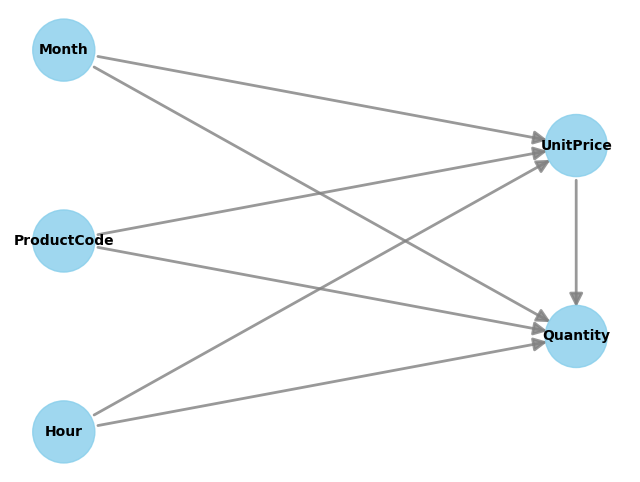

Causal model created.
Treatment: UnitPrice
Outcome: Quantity
Potential confounders: ProductCode, Month, Hour


In [21]:
from dowhy import CausalModel

# Encode product identity as a numeric category
model_data["ProductCode"] = (
    model_data["StockCode"].astype("category").cat.codes
)

causal_data = model_data[
    ["UnitPrice", "Quantity", "ProductCode", "Month", "Hour"]
].dropna().copy()

causal_model = CausalModel(
    data=causal_data,
    treatment="UnitPrice",
    outcome="Quantity",
    common_causes=["ProductCode", "Month", "Hour"]
)

causal_graph = causal_model.view_model()

print("Causal model created.")
print("Treatment: UnitPrice")
print("Outcome: Quantity")
print("Potential confounders: ProductCode, Month, Hour")

In [22]:
identified_estimand = causal_model.identify_effect()

print(identified_estimand)

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
     d                                          
────────────(E[Quantity|Month,ProductCode,Hour])
d[UnitPrice]                                    
Estimand assumption 1, Unconfoundedness: If U→{UnitPrice} and U→Quantity then P(Quantity|UnitPrice,Month,ProductCode,Hour,U) = P(Quantity|UnitPrice,Month,ProductCode,Hour)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

### Estimand : 4
Estimand name: general_adjustment
Estimand expression:
     d                                          
────────────(E[Quantity|Month,ProductCode,Hour])
d[UnitPrice]                                    
Estimand assumption 1, Unconfoundedness: If U→{UnitPrice} and U→Quantity then P(Quantity|UnitPrice,Month,ProductCode,Hour,U) = P(Quantity|UnitPrice,Month,ProductCode,Hour)



ERROR:dowhy.causal_graph:Error: Pygraphviz cannot be loaded. No module named 'pygraphviz'
Trying pydot ...


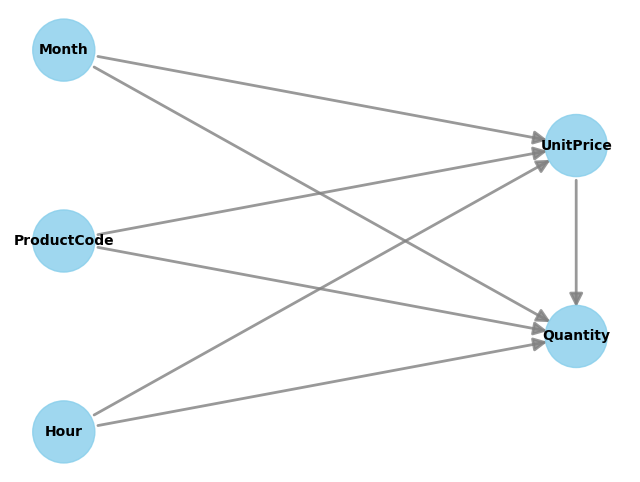

Explicit causal graph created successfully!


In [23]:
from dowhy import CausalModel

# Define the causal assumptions explicitly
causal_graph = """
digraph {
    ProductCode -> UnitPrice;
    ProductCode -> Quantity;
    Month -> UnitPrice;
    Month -> Quantity;
    Hour -> UnitPrice;
    Hour -> Quantity;
    UnitPrice -> Quantity;
}
"""

causal_model = CausalModel(
    data=causal_data,
    treatment="UnitPrice",
    outcome="Quantity",
    graph=causal_graph
)

causal_model.view_model()

print("Explicit causal graph created successfully!")

In [24]:
identified_estimand = causal_model.identify_effect()

print(identified_estimand)

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
     d                                          
────────────(E[Quantity|Month,ProductCode,Hour])
d[UnitPrice]                                    
Estimand assumption 1, Unconfoundedness: If U→{UnitPrice} and U→Quantity then P(Quantity|UnitPrice,Month,ProductCode,Hour,U) = P(Quantity|UnitPrice,Month,ProductCode,Hour)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

### Estimand : 4
Estimand name: general_adjustment
Estimand expression:
     d                                          
────────────(E[Quantity|Month,ProductCode,Hour])
d[UnitPrice]                                    
Estimand assumption 1, Unconfoundedness: If U→{UnitPrice} and U→Quantity then P(Quantity|UnitPrice,Month,ProductCode,Hour,U) = P(Quantity|UnitPrice,Month,ProductCode,Hour)



In [25]:
causal_estimate = causal_model.estimate_effect(
    identified_estimand,
    method_name="backdoor.linear_regression"
)

print("Estimated causal effect:")
print(causal_estimate.value)

Estimated causal effect:
-1.0649827463325803


In [26]:
# EconoCausal: Week 1 - DoWhy refutation test

refutation = causal_model.refute_estimate(
    identified_estimand,
    causal_estimate,
    method_name="random_common_cause"
)

print(refutation)

Refute: Add a random common cause
Estimated effect:-1.0649827463325803
New effect:-1.064981243791744
p value:0.76

